# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Spotify Logistic Regression
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 5th November 2026*

---

Dataset source: [maharshipandya/spotify-tracks-dataset](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset)
## Research question

**Can a tracks speechiness determine if the track is explicit or not?**

This notebook uses a dataset pulled directly from HuggingFace using the `streaming` argument, which contains spotify tracks over a range of 125 different genres, each track with audio features. There are 114,000 rows

The `speechiness` audio feature is used as the predictor and `explicit` is the value to predict


In [1]:
from datasets import load_dataset
from huggingface_hub import login
from data_clean import clean_text, clean_artist
import pandas as pd
import lastfm_creds
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay

HF_KEY = lastfm_creds.HF_KEY

## Loading and cleaning the data

The dataset is streamed in batches of 20,000 rows instead of downloading it all at once. Each batch is converted to a DataFrame, once all the batches are joined into one DataFrame, `dropna()` removes any rows with missing values so the model isn't trained on incomplete records

In [25]:
login(HF_KEY)
dataset = load_dataset("maharshipandya/spotify-tracks-dataset", split="train", streaming=True)

matched_data = []

for batch in dataset.iter(batch_size=20_000):
    
    data = pd.DataFrame(batch)
    # if any data, add to matched_data
    if len(data) > 0:
        matched_data.append(data)
        
spotify = pd.concat(matched_data, ignore_index=True)
spotify = spotify.dropna()
spotify.to_csv('../datasets/spotify.csv', index=False)

## Preparing the data and fitting the model

The data is first reduced to one row per track using `drop_duplicates`, then any rows missing `speechiness` or `explicit` are dropped, to make sure each track counts just once

`speechiness` is the only feature and `explicit` is the target. The data is split 80/20 with `random_state=42` so the result is repeatable.

The feature is scaled with `StandardScaler`, fit on the training set only and applied to the test set

The model is a `LogisticRegression` with `class_weight='balanced'` because clean tracks heavily outnumber explicit ones. Without balancing, the model could end up just predict "clean" for everything and still look accurate.

In [17]:
track_col = 'track_name' if 'track_name' in spotify.columns else 'song'

tracks_feat = (
    spotify
    .drop_duplicates(subset=[track_col])
    .dropna(subset=['speechiness', 'explicit'])
)

# use speechiness as the single feature for the sigmoid curve
X = tracks_feat[['speechiness']]  
y = tracks_feat['explicit']

# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# fit classifier with class balancing
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_scaled, y_train)

# evaluate
y_pred = model.predict(X_test_scaled)
print("accuracy:", accuracy_score(y_test, y_pred))
print("\nclassification report:\n", classification_report(y_test, y_pred, zero_division=0))

accuracy: 0.8299144138024724

classification report:
               precision    recall  f1-score   support

       False       0.95      0.86      0.90     13499
        True       0.25      0.52      0.34      1223

    accuracy                           0.83     14722
   macro avg       0.60      0.69      0.62     14722
weighted avg       0.89      0.83      0.86     14722



## Results and evaluation

The model reaches roughly 83% accuracy, which sounds strong at first glance, but most tracks in the dataset are clean

- **Clean tracks (`False`):** precision 0.95 and recall 0.86. The model is very good at confirming clean songs
- **Explicit tracks (`True`):** precision 0.25 and recall 0.52. It catches about half of the explicit tracks, but also raises a lot of false alarms

The low precision shows that speechiness alone doesn't separate the two classes cleanly

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


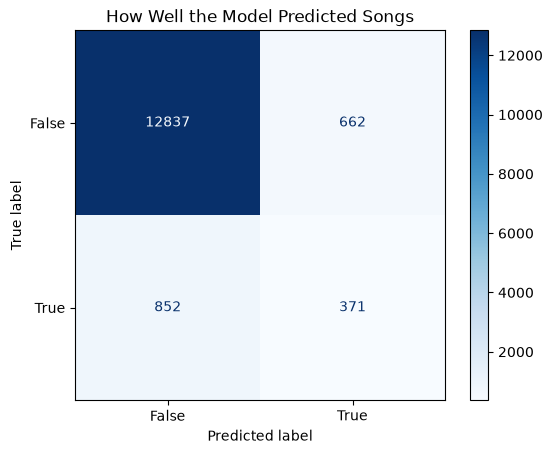

In [14]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title('How Well the Model Predicted Songs')
plt.show()

The confusion matrix shows the same output visually.

Most of the mass sits on the correct diagonal for clean tracks, while the explicit row is split roughly in half between correct predictions and false negatives

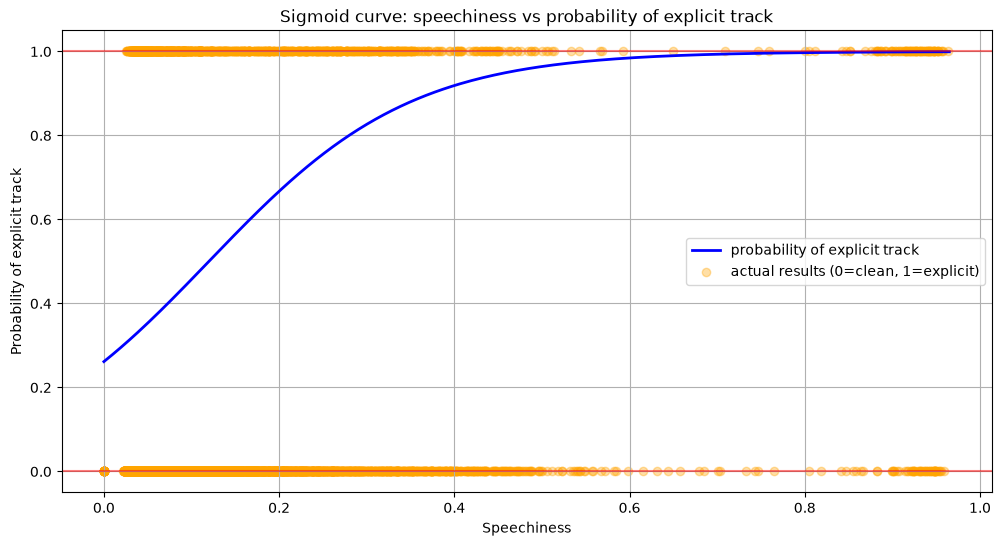

In [19]:
# generate smooth curve data
x_curve = np.linspace(X['speechiness'].min(), X['speechiness'].max(), 300)
x_curve_scaled = scaler.transform(pd.DataFrame({'speechiness': x_curve}))
y_curve = model.predict_proba(x_curve_scaled)[:, 1]

# plot sigmoid curve
plt.figure(figsize=(12, 6))
plt.plot(x_curve, y_curve, color='blue', label='probability of explicit track', linewidth=2)
plt.title('Sigmoid curve: speechiness vs probability of explicit track')
plt.ylabel('Probability of explicit track')
plt.xlabel('Speechiness')

# add visual anchors
plt.axhline(1, color='red', alpha=0.5)
plt.axhline(0, color='red', alpha=0.5)

# scatter actual test results
plt.scatter(X_test['speechiness'], y_test, color='orange', alpha=0.35, label='actual results (0=clean, 1=explicit)')
plt.legend()
plt.grid()
plt.show()

The curve rises as speechiness increases, which backs up the thought that tracks with more "speechiness" content are more likely to be explicit 

## Conclusion

The model comfortably beats a majority-class baseline, and the shape of the curve matches the idea that spoken-word tracks are more likely to be explicit. 

The classification report highlights the issues, precision on explicit tracks is low (0.25), meaning the model raises a lot of false positives, and recall 0.52, so it misses around half of the explicit tracks in the test set

This shows that a single audio feature is not enough to reliably predict whether a track is explicit. 

Speechiness measures how much of a track is spoken rather than sung, but it says nothing about **what** is being said. Features like genre, energy, valence, or actually analysing the lyrics would likely be needed for a stronger model

These results indicate that a simple one-feature baseline is not enough to predict a comprehensive outcome

### Sources
- [HuggingFace spotify-tracks-dataset](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset)